In [1]:
import pandas as pd, matplotlib.pyplot as plt
from matplotlib_venn import venn3

D = "../module2_parkinsons/data/"
gw   = pd.read_csv(D + "pd_gwas.tsv",    sep="\t")
rna  = pd.read_csv(D + "pd_rna.tsv",     sep="\t")
prot = pd.read_csv(D + "pd_protein.tsv", sep="\t")
print(len(gw), len(rna), len(prot))      # expect 393, 20799, 1779


393 20799 1779


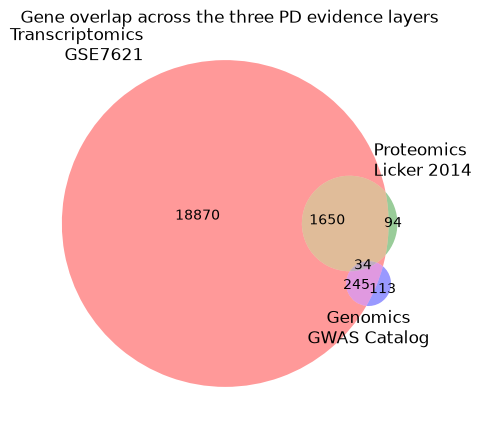

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
venn3([set(rna.gene), set(prot.gene), set(gw.gene)],
      ("Transcriptomics\nGSE7621", "Proteomics\nLicker 2014", "Genomics\nGWAS Catalog"), ax=ax)
ax.set_title("Gene overlap across the three PD evidence layers")
plt.savefig("fig_venn.png", dpi=200, bbox_inches="tight"); plt.show()

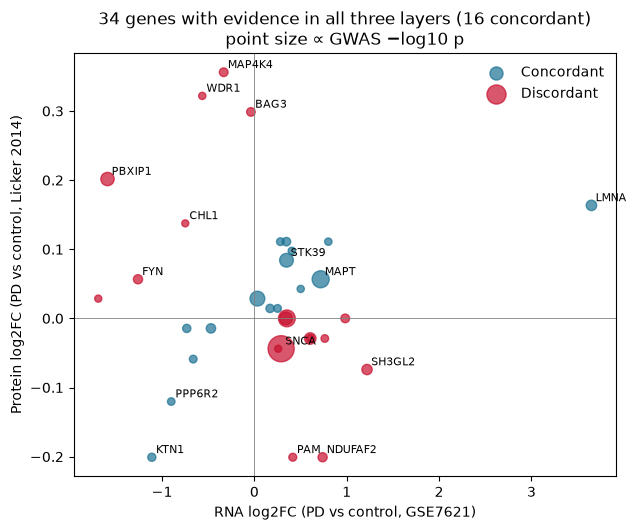

34 16


In [3]:
m = (rna.merge(prot, on="gene", suffixes=("_rna", "_prot"))
        .merge(gw, on="gene"))
m["concordant"] = (m.log2fc_rna > 0) == (m.log2fc_prot > 0)
top = pd.read_csv("../module2_parkinsons/targets_parkinsons.csv")["gene"].head(15)

fig, ax = plt.subplots(figsize=(7, 5.5))
for conc, col, lab in [(True, "#1C7293", "Concordant"), (False, "#C8102E", "Discordant")]:
    s = m[m.concordant == conc]
    ax.scatter(s.log2fc_rna, s.log2fc_prot, s=s.neglog10p * 2 + 15, c=col, alpha=0.7, label=lab)
for _, r in m[m.gene.isin(top)].iterrows():
    ax.annotate(r.gene, (r.log2fc_rna, r.log2fc_prot), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, c="grey", lw=0.6); ax.axvline(0, c="grey", lw=0.6)
ax.set_xlabel("RNA log2FC (PD vs control, GSE7621)")
ax.set_ylabel("Protein log2FC (PD vs control, Licker 2014)")
ax.set_title(f"34 genes with evidence in all three layers ({int(m.concordant.sum())} concordant)\npoint size ∝ GWAS −log10 p")
ax.legend(frameon=False)
plt.savefig("fig_integration.png", dpi=200, bbox_inches="tight"); plt.show()
print(len(m), int(m.concordant.sum()))   # expect 34, 16